In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"

In [3]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_vehicle.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_empa.nc")

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,2.767,0.303,2.218,3.363,0.008,0.006,1380.0,1667.0,1.0
band[low_frequency],-1.982,0.052,-2.081,-1.889,0.001,0.001,3530.0,2133.0,1.0
gtyp[fa/fa],0.263,0.458,-0.591,1.147,0.013,0.009,1207.0,1837.0,1.0
age[Young],0.036,0.458,-0.793,0.872,0.012,0.010,1421.0,1585.0,1.0
sex[M],-0.328,0.426,-1.107,0.495,0.011,0.008,1571.0,1943.0,1.0
"gtyp:age[fa/fa, Young]",-0.099,0.611,-1.296,1.045,0.017,0.014,1302.0,1808.0,1.0
"gtyp:sex[fa/fa, M]",-0.694,0.586,-1.812,0.423,0.016,0.011,1419.0,1710.0,1.0
1|rat_sigma,0.815,0.121,0.604,1.046,0.004,0.003,1167.0,1707.0,1.0
sigma_Intercept,-0.176,0.029,-0.234,-0.122,0.001,0.001,3408.0,2393.0,1.0
sigma_band[low_frequency],0.253,0.047,0.162,0.339,0.001,0.001,3569.0,2537.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,2.122,0.243,1.641,2.573,0.007,0.005,1112.0,1552.0,1.0
band[low_frequency],-1.576,0.047,-1.663,-1.485,0.001,0.001,3197.0,2700.0,1.0
gtyp[fa/fa],0.247,0.373,-0.430,0.936,0.011,0.008,1221.0,1581.0,1.0
age[Young],-0.327,0.343,-0.983,0.324,0.010,0.007,1079.0,1728.0,1.0
sex[M],0.112,0.334,-0.490,0.771,0.009,0.007,1247.0,1711.0,1.0
"gtyp:age[fa/fa, Young]",0.659,0.481,-0.190,1.695,0.014,0.011,1155.0,1445.0,1.0
"gtyp:sex[fa/fa, M]",-1.263,0.477,-2.160,-0.364,0.013,0.010,1249.0,1685.0,1.0
1|rat_sigma,0.675,0.098,0.496,0.857,0.003,0.002,913.0,1213.0,1.0
sigma_Intercept,-0.140,0.030,-0.198,-0.086,0.001,0.000,2453.0,2328.0,1.0
sigma_band[low_frequency],0.103,0.046,0.017,0.190,0.001,0.001,2678.0,2505.0,1.0


In [5]:
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["baseline_power_vehicle"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["baseline_power_empa"])

## Posterior predictive checks

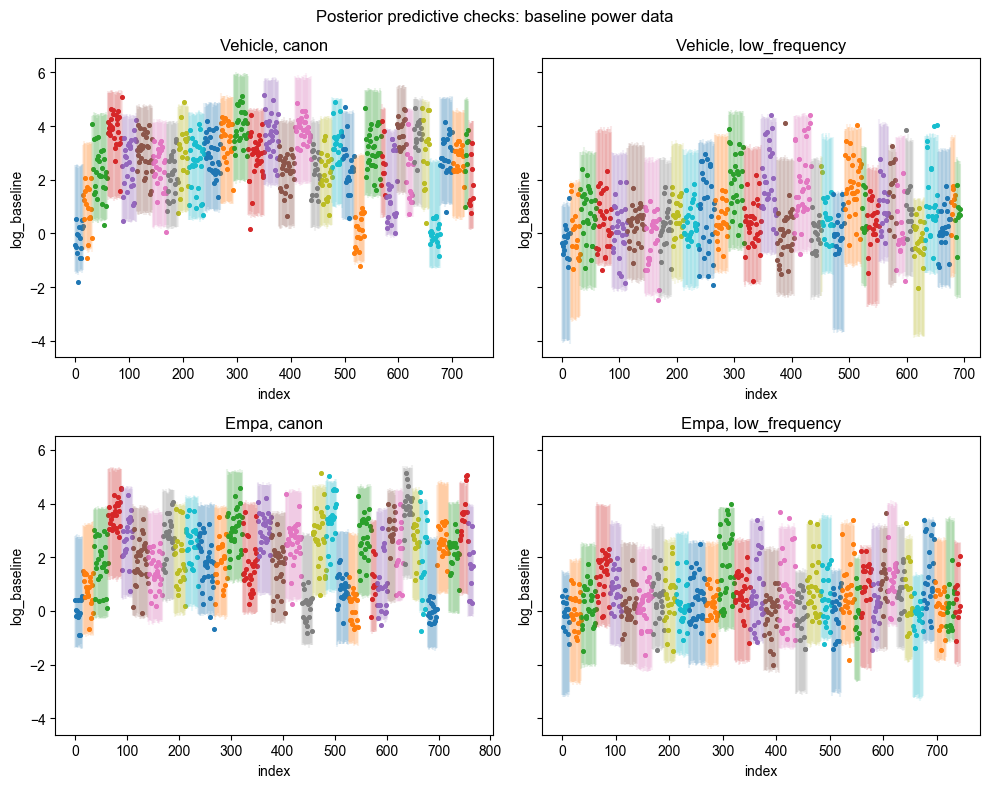

In [6]:
PLOT_DIR_NEW.mkdir(exist_ok=True)
f, axes = plt.subplots(2, 2, figsize=[10, 8], sharey=True)
for ax_row, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    for ax, band in zip(ax_row, ("canon", "low_frequency")):
        is_band = (msts["band"] == band).to_numpy()
        ax = plot_ppc(ax, idata.isel(__obs__=is_band), msts.filter(is_band), ycol="log_baseline", groupcol="rat")
        ax.set_title(f"{name.capitalize()}, {band}");
        ax.get_legend().remove()

f.suptitle("Posterior predictive checks: baseline power data");
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_baseline_power.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%-99% posterior predictive intervals.

## Effects

Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa - fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.

In [7]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="TS (ln baseline power)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups)
    for idata, t_groups in ((idata_vehicle, t_groups_vehicle), (idata_empa, t_groups_empa))
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

### Overall effects

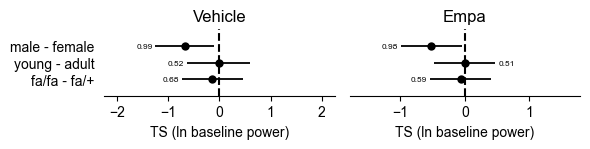

In [8]:
f, axes = plot_effects(overall_ts_vehicle, overall_ts_empa, figsize=(6, 1.6))
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_baseline_power_overall.png", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

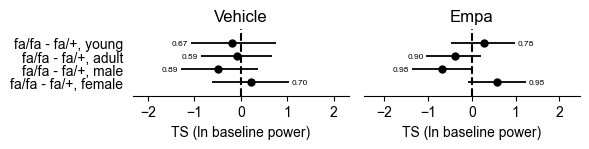

In [9]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(6, 1.6))
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_baseline_power_gtyp_given_sex_age.png", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [10]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (overall_ts_vehicle, overall_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
        )
    ],
    keys=("overall", "gtyp given sex/age"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif     empa  \
contrast           group                                                   
overall            fa/fa - fa/+          0.32100                 0.41425   
                   young - adult         0.47850                 0.50525   
                   male - female         0.01100              *  0.01725   
gtyp given sex/age fa/fa - fa/+, female  0.70250                 0.95375   
                   fa/fa - fa/+, male    0.11275                 0.01800   
                   fa/fa - fa/+, adult   0.41225                 0.09650   
                   fa/fa - fa/+, young   0.32725                 0.77975   

                                        empa_signif  
contrast           group                             
overall            fa/fa - fa/+                      
                   young - adult                     
                   male - female                  *  
gtyp given sex/age fa/fa - fa/+, female              
                   fa/fa - fa/+, male             *  
                   fa/fa - fa/+, adult               
                   fa/fa - fa/+, young